# **Lab 7(B) - Mathematical and Statistical Filters (Solved)**

In [1]:
import cv2
import numpy as np
from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)
np.random.seed(42)     # reproducible noise

## 1. Adding noise to an image
`noise.jpg` is the clean reference image. We generate 4 noisy versions: **Gaussian, Salt & Pepper, Exponential, Uniform**.

PSNR of noisy images vs. clean image:
  Gaussian    : 20.85 dB
  Salt&Pepper : 18.52 dB
  Exponential : 25.69 dB
  Uniform     : 26.87 dB


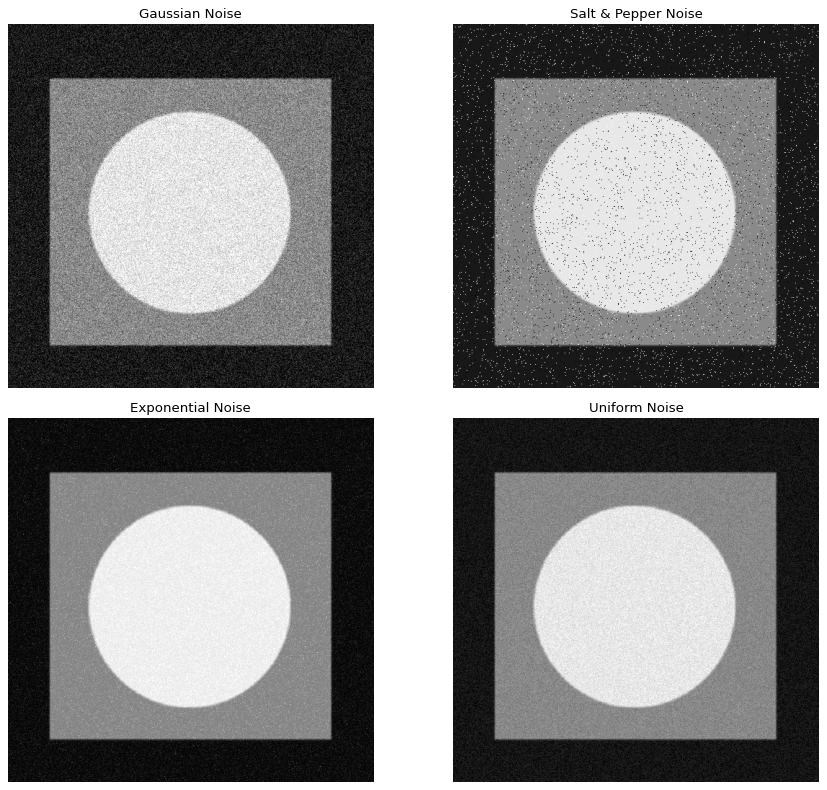

In [2]:
# ========== ( Adding noise to an Image ) =================
imgPath = 'noise.jpg'
img = cv2.imread(imgPath, 0)

def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low, high = -20, 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)

noise_gauss = add_noise(img, "gaussian")
noise_sp    = add_noise(img, "salt_pepper")
noise_expo  = add_noise(img, "exponential")
noise_uni   = add_noise(img, "uniform")

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'),    plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'),  plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'),   plt.title('Uniform Noise')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

# Helper: PSNR (higher = closer to the clean image)
def psnr(a, b): return cv2.PSNR(a, b)
print("PSNR of noisy images vs. clean image:")
for n, im in [("Gaussian", noise_gauss), ("Salt&Pepper", noise_sp), ("Exponential", noise_expo), ("Uniform", noise_uni)]:
    print(f"  {n:12s}: {psnr(img, im):.2f} dB")

## 2. Arithmetic Mean Filter
`f(x,y) = (1/mn) · Σ g(s,t)` - smooths the image; **best for Gaussian / Uniform noise** (but blurs edges).

Method 1 == Method 2 ? True
PSNR noisy=20.85 | 3x3=30.01 | 5x5=32.82 | 7x7=32.67


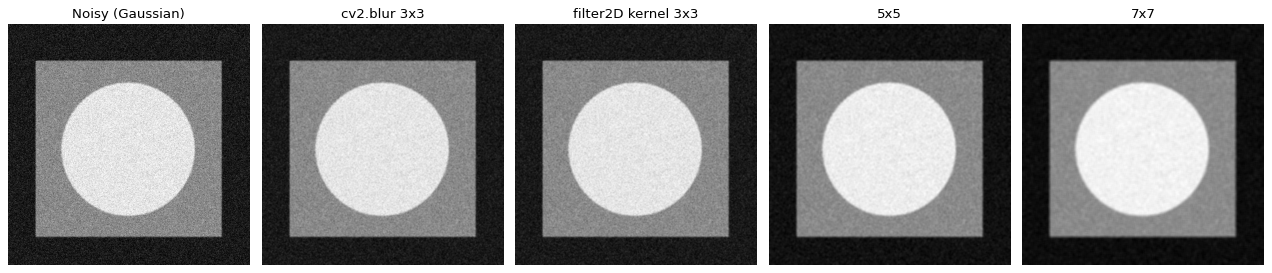

In [3]:
# --- METHOD 1: Built-in OpenCV function ---
mean_builtin = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual kernel (matrix of 1s / number of pixels) ---
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
# NOTE: filter the NOISY image (the original code filtered the clean `img` by mistake)
mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

print("Method 1 == Method 2 ?", np.allclose(mean_builtin.astype(int), mean_manual.astype(int), atol=1))

# Try different window sizes
mean5 = cv2.blur(noise_gauss, (5, 5))
mean7 = cv2.blur(noise_gauss, (7, 7))

plt.figure(figsize=(16, 4))
for i, (im, t) in enumerate([(noise_gauss,'Noisy (Gaussian)'), (mean_builtin,'cv2.blur 3x3'),
                             (mean_manual,'filter2D kernel 3x3'), (mean5,'5x5'), (mean7,'7x7')]):
    plt.subplot(1, 5, i+1), plt.imshow(im, cmap='gray'), plt.title(t), plt.axis('off')
plt.tight_layout()
plt.show()

print(f"PSNR noisy={psnr(img, noise_gauss):.2f} | 3x3={psnr(img, mean_builtin):.2f} | 5x5={psnr(img, mean5):.2f} | 7x7={psnr(img, mean7):.2f}")

## 3. Geometric Mean Filter
`f(x,y) = [ Π g(s,t) ]^(1/mn)` - smoothing similar to the arithmetic mean but **loses less detail**. Implemented with `exp(mean(log(g)))`.

PSNR noisy=20.85 dB -> geometric mean=24.18 dB


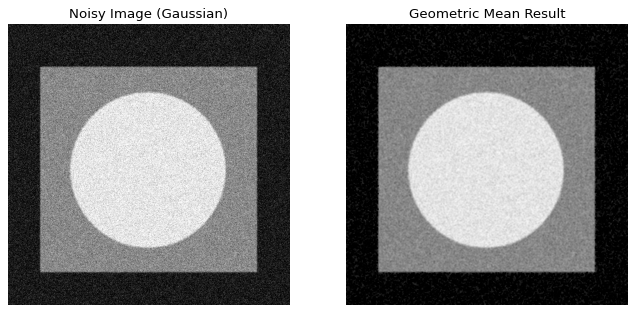

In [4]:
def geometric_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6          # avoid log(0)
    log_img = np.log(img_float)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)
    geo_mean = np.exp(mean_log)
    return np.clip(geo_mean, 0, 255).astype(np.uint8)

noise_img = noise_gauss
result_geo = geometric_mean_filter(noise_img, kernel_size=3)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'),  plt.title('Noisy Image (Gaussian)'), plt.axis('off')
plt.subplot(122), plt.imshow(result_geo, cmap='gray'), plt.title('Geometric Mean Result'),  plt.axis('off')
plt.show()
print(f"PSNR noisy={psnr(img, noise_img):.2f} dB -> geometric mean={psnr(img, result_geo):.2f} dB")

## 4. Harmonic Mean Filter
`f(x,y) = mn / Σ (1/g(s,t))` - works well for **Gaussian and salt noise**, but **fails on pepper noise** (a 0 pixel makes `1/g` huge).

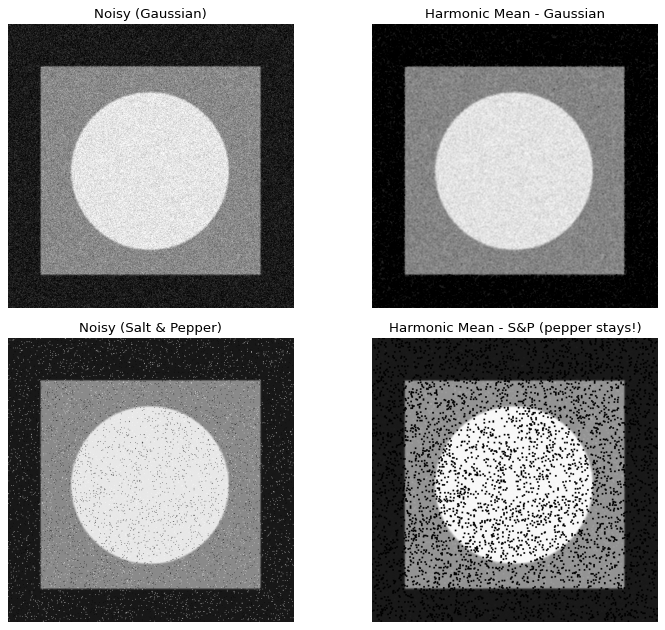

In [5]:
def harmonic_mean_filter(image, kernel_size=3):
    img_float = image.astype(np.float64) + 1e-6
    reciprocal_img = 1.0 / img_float
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)

harm_gauss = harmonic_mean_filter(noise_gauss, 3)
harm_sp    = harmonic_mean_filter(noise_sp, 3)

plt.figure(figsize=(14, 8))
plt.subplot(231), plt.imshow(noise_gauss, cmap='gray'), plt.title('Noisy (Gaussian)')
plt.subplot(232), plt.imshow(harm_gauss, cmap='gray'),  plt.title('Harmonic Mean - Gaussian')
plt.subplot(234), plt.imshow(noise_sp, cmap='gray'),    plt.title('Noisy (Salt & Pepper)')
plt.subplot(235), plt.imshow(harm_sp, cmap='gray'),     plt.title('Harmonic Mean - S&P (pepper stays!)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Contra-Harmonic Mean Filter
`f(x,y) = Σ g^(Q+1) / Σ g^Q`

* `Q > 0` -> eliminates **pepper** noise (black dots)
* `Q < 0` -> eliminates **salt** noise (white dots)
* `Q = 0` -> arithmetic mean, `Q = -1` -> harmonic mean

It must **not** be applied with the wrong sign (e.g. Q>0 on salt noise makes it worse). We use the provided `salt_Pepper.jpg` / `salt_Pepper2.jpg` images, which contain mostly pepper (dark) dots plus a few salt (white) dots.

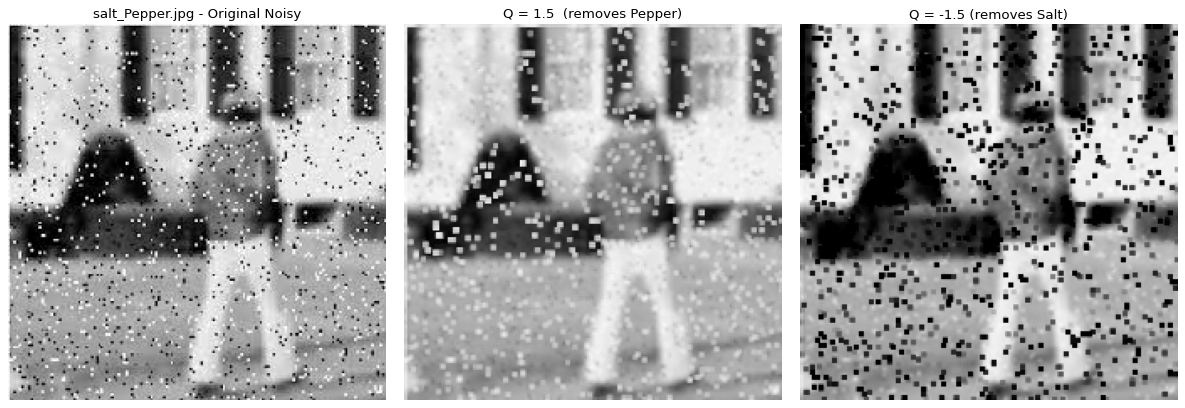

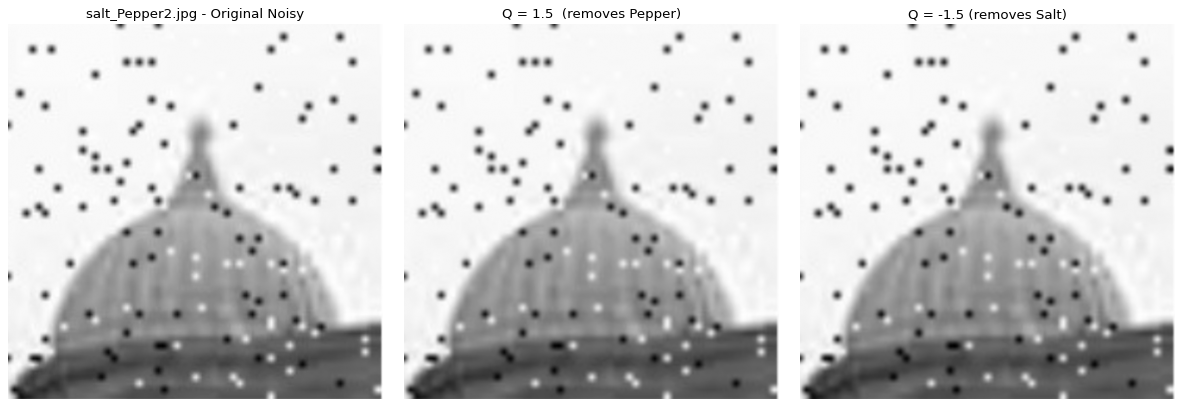

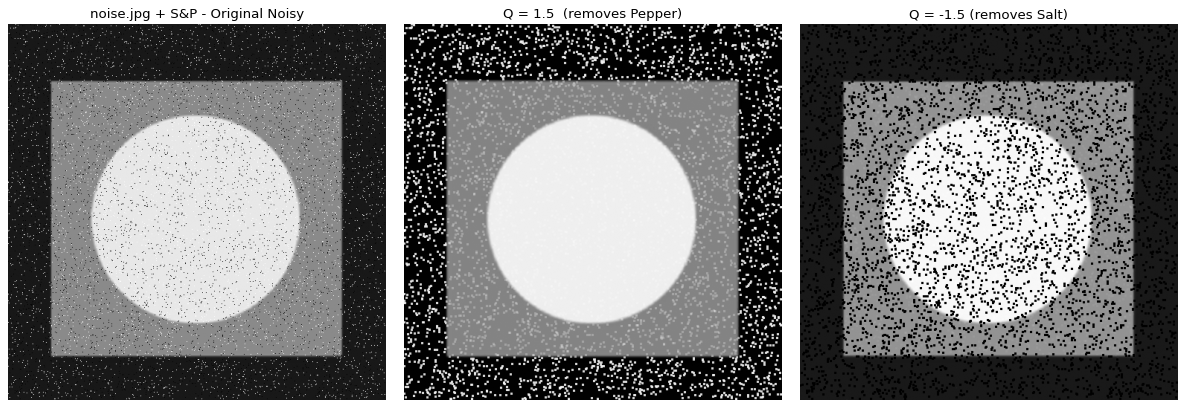

In [6]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    img_float = image.astype(np.float64) + 1e-6
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(np.power(img_float, Q + 1), -1, kernel)
    den_sum = cv2.filter2D(np.power(img_float, Q), -1, kernel)
    result = num_sum / (den_sum + 1e-12)
    return np.clip(result, 0, 255).astype(np.uint8)

sp1 = cv2.imread('salt_Pepper.jpg', 0)
sp2 = cv2.imread('salt_Pepper2.jpg', 0)

def show_contra(noisy, name):
    pepper_removed = contra_harmonic_mean(noisy, 3,  1.5)    # Q > 0  -> removes pepper
    salt_removed   = contra_harmonic_mean(noisy, 3, -1.5)    # Q < 0  -> removes salt
    plt.figure(figsize=(15, 5))
    plt.subplot(131), plt.imshow(noisy, cmap='gray'),          plt.title(f'{name} - Original Noisy')
    plt.subplot(132), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q = 1.5  (removes Pepper)')
    plt.subplot(133), plt.imshow(salt_removed, cmap='gray'),   plt.title('Q = -1.5 (removes Salt)')
    for ax in plt.gcf().axes: ax.axis('off')
    plt.tight_layout()
    plt.show()

show_contra(sp1, 'salt_Pepper.jpg')
show_contra(sp2, 'salt_Pepper2.jpg')
show_contra(noise_sp, 'noise.jpg + S&P')

## 6. Median Filter
Replaces each pixel by the **median** of its neighbourhood. Best filter for **Salt & Pepper (impulse) noise** with very little blurring.

PSNR S&P noisy=18.52 | median3=50.67 | median5=50.64 | mean3=27.52


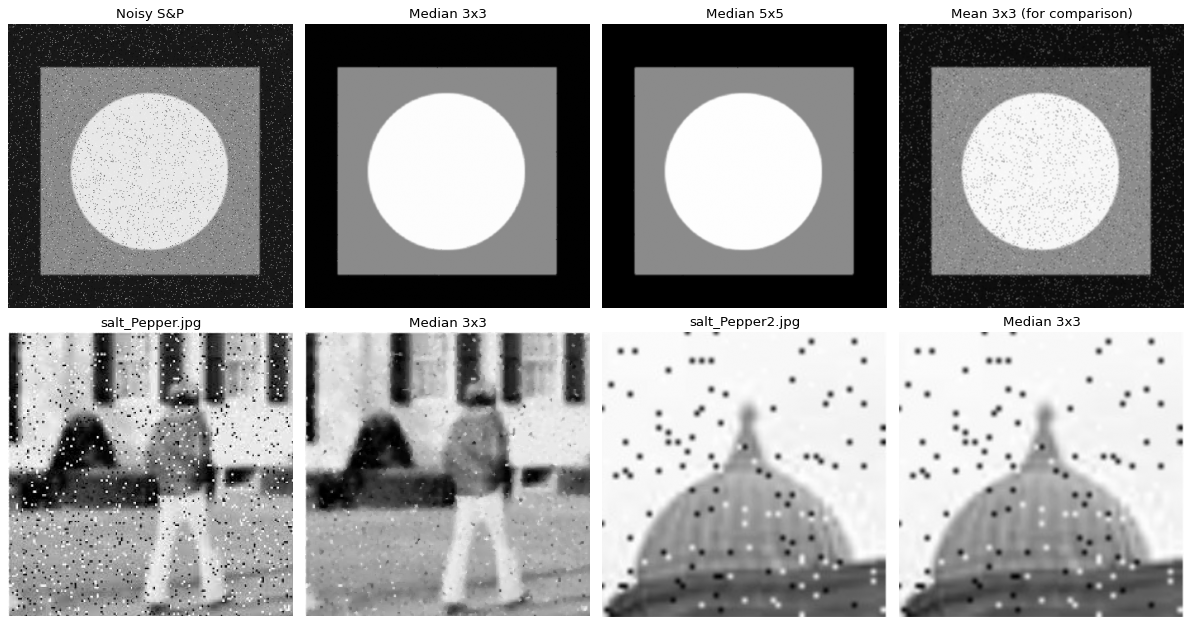

In [7]:
median_sp   = cv2.medianBlur(noise_sp, 3)
median_sp5  = cv2.medianBlur(noise_sp, 5)
median_sp1  = cv2.medianBlur(sp1, 3)
median_sp2  = cv2.medianBlur(sp2, 3)

plt.figure(figsize=(15, 8))
plt.subplot(241), plt.imshow(noise_sp, cmap='gray'),   plt.title('Noisy S&P')
plt.subplot(242), plt.imshow(median_sp, cmap='gray'),  plt.title('Median 3x3')
plt.subplot(243), plt.imshow(median_sp5, cmap='gray'), plt.title('Median 5x5')
plt.subplot(244), plt.imshow(cv2.blur(noise_sp,(3,3)), cmap='gray'), plt.title('Mean 3x3 (for comparison)')
plt.subplot(245), plt.imshow(sp1, cmap='gray'),        plt.title('salt_Pepper.jpg')
plt.subplot(246), plt.imshow(median_sp1, cmap='gray'), plt.title('Median 3x3')
plt.subplot(247), plt.imshow(sp2, cmap='gray'),        plt.title('salt_Pepper2.jpg')
plt.subplot(248), plt.imshow(median_sp2, cmap='gray'), plt.title('Median 3x3')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()
print(f"PSNR S&P noisy={psnr(img, noise_sp):.2f} | median3={psnr(img, median_sp):.2f} | median5={psnr(img, median_sp5):.2f} | mean3={psnr(img, cv2.blur(noise_sp,(3,3))):.2f}")

## 7. Max and Min Filters
* **Max filter** (dilation) takes the brightest pixel -> removes **pepper** (but enlarges salt)
* **Min filter** (erosion) takes the darkest pixel -> removes **salt** (but enlarges pepper)

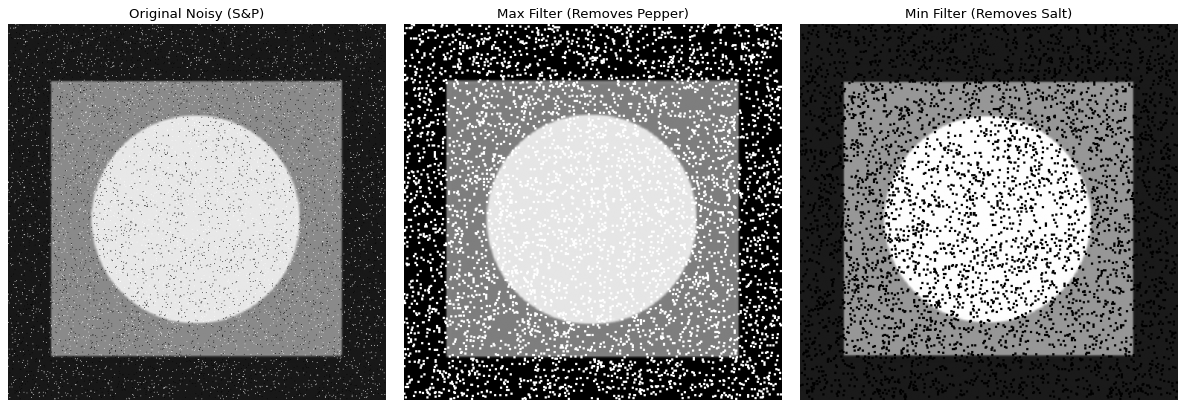

In [8]:
kernel = np.ones((3, 3), np.uint8)

max_filter = cv2.dilate(noise_sp, kernel)   # Max
min_filter = cv2.erode(noise_sp, kernel)    # Min

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_sp, cmap='gray'),    plt.title('Original Noisy (S&P)')
plt.subplot(132), plt.imshow(max_filter, cmap='gray'),  plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter, cmap='gray'),  plt.title('Min Filter (Removes Salt)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 8. Mid-Point Filter
`f(x,y) = ½ [ max(g) + min(g) ]` - combines order statistics with averaging; best for **randomly distributed noise such as Gaussian and Uniform**.

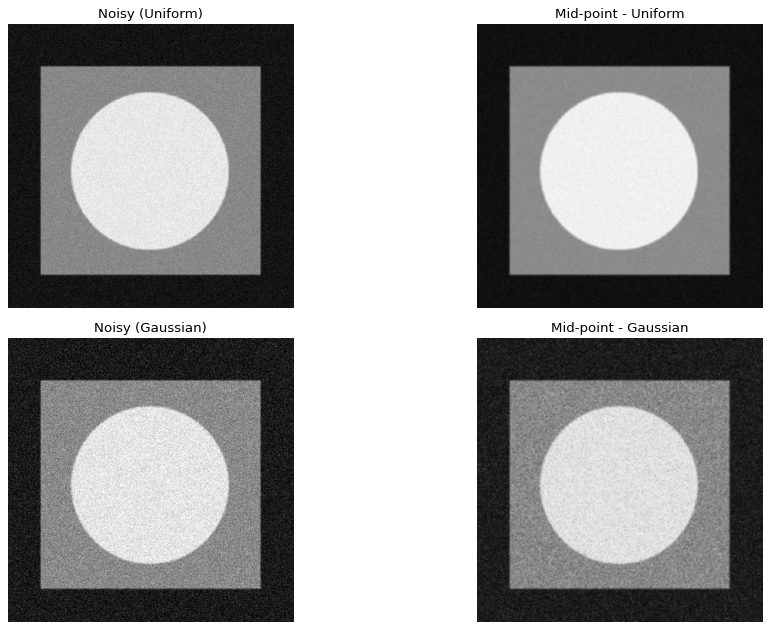

In [9]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    max_img = cv2.dilate(image, kernel).astype(np.float64)
    min_img = cv2.erode(image, kernel).astype(np.float64)
    return ((max_img + min_img) / 2).astype(np.uint8)

mid_uni   = midpoint_filter(noise_uni, 3)
mid_gauss = midpoint_filter(noise_gauss, 3)

plt.figure(figsize=(14, 8))
plt.subplot(221), plt.imshow(noise_uni, cmap='gray'),   plt.title('Noisy (Uniform)')
plt.subplot(222), plt.imshow(mid_uni, cmap='gray'),     plt.title('Mid-point - Uniform')
plt.subplot(223), plt.imshow(noise_gauss, cmap='gray'), plt.title('Noisy (Gaussian)')
plt.subplot(224), plt.imshow(mid_gauss, cmap='gray'),   plt.title('Mid-point - Gaussian')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 9. Summary - every filter on every noise type (PSNR in dB, higher is better)

In [10]:
noisy = {"Gaussian": noise_gauss, "Salt&Pepper": noise_sp, "Exponential": noise_expo, "Uniform": noise_uni}

filters = {
    "Arithmetic mean 3x3": lambda x: cv2.blur(x, (3,3)),
    "Geometric mean 3x3":  lambda x: geometric_mean_filter(x, 3),
    "Harmonic mean 3x3":   lambda x: harmonic_mean_filter(x, 3),
    "Contra-harmonic Q=+1.5": lambda x: contra_harmonic_mean(x, 3, 1.5),
    "Contra-harmonic Q=-1.5": lambda x: contra_harmonic_mean(x, 3, -1.5),
    "Median 3x3":          lambda x: cv2.medianBlur(x, 3),
    "Max 3x3":             lambda x: cv2.dilate(x, np.ones((3,3), np.uint8)),
    "Min 3x3":             lambda x: cv2.erode(x, np.ones((3,3), np.uint8)),
    "Mid-point 3x3":       lambda x: midpoint_filter(x, 3),
}

print(f"{'Filter':26s}" + "".join(f"{n:>13s}" for n in noisy))
print(f"{'(no filter)':26s}" + "".join(f"{psnr(img, v):13.2f}" for v in noisy.values()))
for fname, f in filters.items():
    print(f"{fname:26s}" + "".join(f"{psnr(img, f(v)):13.2f}" for v in noisy.values()))

Filter                         Gaussian  Salt&Pepper  Exponential      Uniform
(no filter)                       20.85        18.52        25.69        26.87
Arithmetic mean 3x3               30.01        27.52        28.21        35.81
Geometric mean 3x3                24.18        14.19        29.31        33.80
Harmonic mean 3x3                 23.44        13.19        29.85        31.25
Contra-harmonic Q=+1.5            23.28        14.04        26.17        32.35
Contra-harmonic Q=-1.5            23.01        13.19        30.28        29.33
Median 3x3                        27.73        50.67        30.19        32.34
Max 3x3                           16.64        11.56        18.77        23.36
Min 3x3                           17.18        13.16        33.44        22.91
Mid-point 3x3                     27.12        15.65        24.99        37.17


## Conclusion - which filter for which noise?

| Noise type | Best filter(s) | Why |
|---|---|---|
| **Gaussian** | Arithmetic mean (best here), then Median / Mid-point | Averaging cancels random zero-mean noise |
| **Uniform** | Mid-point, Arithmetic mean | Bounded random noise -> (max+min)/2 or averaging works well |
| **Exponential** | Min filter, Median, Contra-harmonic Q<0 | Noise is always positive (bright bias), so filters that favour darker pixels do best |
| **Salt & Pepper** | **Median** | Outliers are discarded instead of averaged in |
| **Pepper only** | Contra-harmonic Q>0, Max filter | Bright neighbours dominate |
| **Salt only** | Contra-harmonic Q<0, Min filter, Harmonic mean | Dark neighbours dominate |

* The geometric/harmonic means preserve more detail than the arithmetic mean but are very sensitive to black (0) pixels, so they give poor results on pepper noise.
* The **harmonic mean** handles salt noise but **not pepper**.
* The **contra-harmonic** filter with the wrong sign of Q makes the noise worse.
* Larger kernels remove more noise but blur more edges.